# Riesgo crediticio con Árboles de Decisión y Random Forest

**Integrante: CUSSI NICOLÁS A.**

Predicción de incumplimiento de crédito, comparando un árbol de decisión básico, un árbol optimizado con `GridSearchCV` y un Random Forest, con métricas adecuadas para clases desbalanceadas.

> **Sobre los datos.** Son **sintéticos**, generados con un proceso conocido: la probabilidad de incumplimiento sube con los atrasos previos y con la relación monto/ingresos, y baja levemente con la edad, con un componente aleatorio y una interacción no lineal.
> Esto permite comprobar al final si los modelos recuperan las relaciones reales.
>
> Esta versión reemplaza la entrega original, donde las variables y el objetivo se generaban de forma **independiente** (`np.random`). Sin relación entre ellas, ningún modelo podía rendir mejor que el azar y las conclusiones no se sostenían.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)

sns.set_theme(style="whitegrid")
SEED = 42

## Paso 1: Generación del dataset

3.000 clientes con cuatro variables: `Edad`, `Ingresos` (anuales), `Atrasos_Previos` (cantidad de atrasos en créditos anteriores) y `Monto_Credito`. Se agrega `Ratio_Monto_Ingresos`, un indicador habitual de capacidad de pago.

In [2]:
rng = np.random.default_rng(SEED)
n = 3000

edad = rng.integers(21, 66, n)
ingresos = np.clip(rng.lognormal(np.log(60000), 0.45, n), 20000, 250000).round(-2)
atrasos = np.clip(rng.poisson(0.9, n), 0, 5)
monto = rng.integers(3000, 60000, n)
ratio = monto / ingresos

# Proceso generador (el "mundo real" que los modelos deben descubrir)
logit = (-3.3
         + 0.7 * atrasos                           # más atrasos previos -> más riesgo
         + 2.6 * ratio                             # deuda alta respecto del ingreso -> más riesgo
         - 0.025 * (edad - 40)                     # efecto leve de la edad
         + 0.9 * ((ratio > 0.6) & (atrasos >= 2))) # interacción no lineal
prob = 1 / (1 + np.exp(-logit))

df = pd.DataFrame({
    "Edad": edad,
    "Ingresos": ingresos,
    "Atrasos_Previos": atrasos,
    "Monto_Credito": monto,
    "Ratio_Monto_Ingresos": ratio.round(3),
    "Incumplimiento": rng.binomial(1, prob),
})

print(f"Tasa de incumplimiento: {df['Incumplimiento'].mean():.1%}")
df.head()

Tasa de incumplimiento: 28.9%


,Edad,Ingresos,Atrasos_Previos,Monto_Credito,Ratio_Monto_Ingresos,Incumplimiento
0,25,92500.0,2,8917,0.096,0
1,55,43300.0,1,23583,0.545,1
2,50,40900.0,0,29455,0.720,0
3,40,73800.0,1,33073,0.448,1
4,40,93600.0,0,54316,0.580,0


## Paso 2: Exploración rápida

Hay desbalance de clases (~29 % de incumplimientos) y las dos variables principales muestran una relación clara con el riesgo.

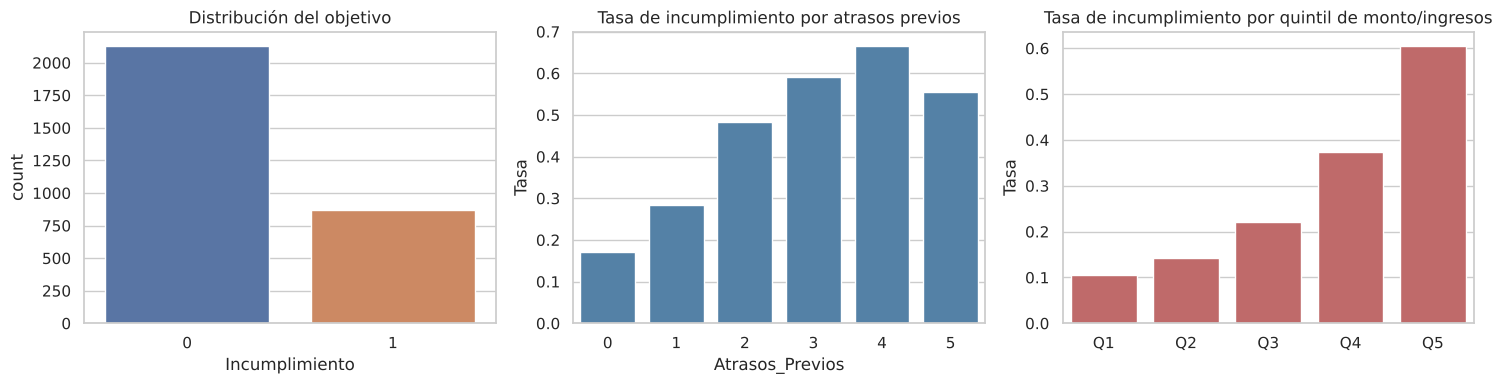

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(x="Incumplimiento", data=df, ax=axes[0], hue="Incumplimiento", legend=False)
axes[0].set_title("Distribución del objetivo")

tasa_atrasos = df.groupby("Atrasos_Previos")["Incumplimiento"].mean()
sns.barplot(x=tasa_atrasos.index, y=tasa_atrasos.values, ax=axes[1], color="steelblue")
axes[1].set_title("Tasa de incumplimiento por atrasos previos")
axes[1].set_ylabel("Tasa")

tramos = pd.qcut(df["Ratio_Monto_Ingresos"], 5)
tasa_ratio = df.groupby(tramos, observed=True)["Incumplimiento"].mean()
sns.barplot(x=[f"Q{i+1}" for i in range(5)], y=tasa_ratio.values, ax=axes[2], color="indianred")
axes[2].set_title("Tasa de incumplimiento por quintil de monto/ingresos")
axes[2].set_ylabel("Tasa")

plt.tight_layout()
plt.show()

## Paso 3: Partición y modelo de referencia

- La partición es **estratificada**, para que train y test mantengan la misma proporción de incumplimientos.
- **No se escalan las variables:** los árboles y Random Forest deciden por umbrales y no se ven afectados por la escala. (En la entrega original se escalaba antes de dividir, lo que además filtra información del test al entrenamiento.)
- Se define un **modelo de referencia** que siempre predice "cumple". Sirve para entender por qué el accuracy solo no alcanza.

In [4]:
X = df.drop(columns="Incumplimiento")
y = df["Incumplimiento"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)

def evaluar(nombre, modelo):
    pred = modelo.predict(X_test)
    proba = modelo.predict_proba(X_test)[:, 1]
    return {"Modelo": nombre,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred),
            "ROC-AUC": roc_auc_score(y_test, proba)}

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
resultados = [evaluar("Referencia (siempre 'cumple')", dummy)]
pd.DataFrame(resultados).round(3)

,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC
0,Referencia (siempre 'cumple'),0.71,0.0,0.0,0.0,0.5


La referencia acierta ~71 % sin detectar **ningún** incumplimiento (recall 0). Por eso, además del accuracy se miran **recall, F1 y ROC-AUC**.

## Paso 4: Árbol de decisión básico

Sin restricciones de profundidad, el árbol memoriza el entrenamiento.

In [5]:
arbol_basico = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)

print(f"Profundidad: {arbol_basico.get_depth()} | Hojas: {arbol_basico.get_n_leaves()}")
print(f"Accuracy train: {arbol_basico.score(X_train, y_train):.3f}")
print(f"Accuracy test:  {arbol_basico.score(X_test, y_test):.3f}")

resultados.append(evaluar("Árbol básico", arbol_basico))
print()
print(classification_report(y_test, arbol_basico.predict(X_test),
                            target_names=["Cumple", "Incumple"]))

Profundidad: 27 | Hojas: 493
Accuracy train: 1.000
Accuracy test:  0.692

              precision    recall  f1-score   support

      Cumple       0.80      0.75      0.78       426
    Incumple       0.47      0.55      0.51       174

    accuracy                           0.69       600
   macro avg       0.64      0.65      0.64       600
weighted avg       0.71      0.69      0.70       600



Accuracy de 100 % en entrenamiento contra un valor mucho menor en prueba: es **sobreajuste**.

## Paso 5: Optimización con GridSearchCV

Se busca la mejor combinación de profundidad, tamaño mínimo de hoja y ponderación de clases, con validación cruzada estratificada de 5 folds. Se optimiza **ROC-AUC** y no accuracy, porque el accuracy premia predecir siempre la clase mayoritaria.

In [6]:
param_grid = {
    "max_depth": [3, 4, 5, 6, 8],
    "min_samples_leaf": [5, 10, 20, 40],
    "class_weight": [None, "balanced"],
}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=SEED),
    param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
    scoring="roc_auc",
    n_jobs=-1,
)
grid.fit(X_train, y_train)

print("Mejores hiperparámetros:", grid.best_params_)
print(f"ROC-AUC en validación cruzada: {grid.best_score_:.3f}")

arbol_opt = grid.best_estimator_
resultados.append(evaluar("Árbol optimizado", arbol_opt))
print()
print(classification_report(y_test, arbol_opt.predict(X_test),
                            target_names=["Cumple", "Incumple"]))

Mejores hiperparámetros: {'class_weight': 'balanced', 'max_depth': 4, 'min_samples_leaf': 40}
ROC-AUC en validación cruzada: 0.809

              precision    recall  f1-score   support

      Cumple       0.84      0.81      0.83       426
    Incumple       0.58      0.61      0.59       174

    accuracy                           0.76       600
   macro avg       0.71      0.71      0.71       600
weighted avg       0.76      0.76      0.76       600



## Paso 6: Random Forest

Un ensamble de árboles reduce la varianza del árbol individual. Se usa `class_weight="balanced"` para no ignorar la clase minoritaria.

In [7]:
rf = RandomForestClassifier(
    n_estimators=300, min_samples_leaf=5, class_weight="balanced",
    random_state=SEED, n_jobs=-1,
).fit(X_train, y_train)

resultados.append(evaluar("Random Forest", rf))
print(classification_report(y_test, rf.predict(X_test),
                            target_names=["Cumple", "Incumple"]))

              precision    recall  f1-score   support

      Cumple       0.84      0.78      0.81       426
    Incumple       0.54      0.64      0.59       174

    accuracy                           0.74       600
   macro avg       0.69      0.71      0.70       600
weighted avg       0.75      0.74      0.74       600



## Paso 7: Comparación de modelos

In [8]:
tabla = pd.DataFrame(resultados).set_index("Modelo").round(3)
tabla

,Accuracy,Precision,Recall,F1,ROC-AUC
Modelo,,,,,
Referencia (siempre 'cumple'),0.710,0.000,0.000,0.000,0.500
Árbol básico,0.692,0.473,0.546,0.507,0.649
Árbol optimizado,0.757,0.575,0.615,0.594,0.772
Random Forest,0.738,0.541,0.644,0.588,0.790


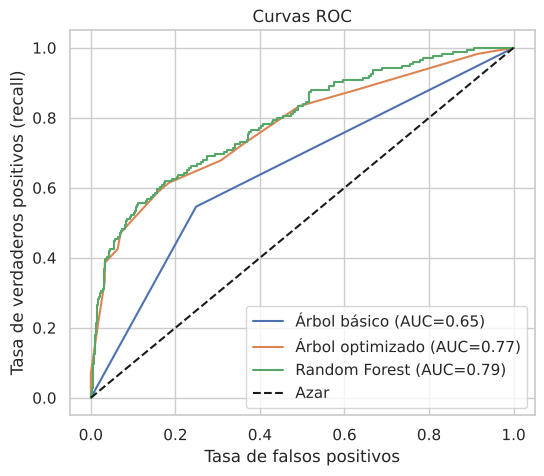

In [9]:
modelos = {"Árbol básico": arbol_basico, "Árbol optimizado": arbol_opt, "Random Forest": rf}

plt.figure(figsize=(6, 5))
for nombre, m in modelos.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    auc = roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{nombre} (AUC={auc:.2f})")
plt.plot([0, 1], [0, 1], "k--", label="Azar")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos (recall)")
plt.title("Curvas ROC")
plt.legend()
plt.show()

## Paso 8: ¿Los modelos descubrieron las relaciones reales?

Como conocemos el proceso generador, se puede verificar. Se usa **importancia por permutación** sobre el conjunto de prueba (cuánto empeora el ROC-AUC al desordenar cada variable), más confiable que la importancia interna de los árboles.

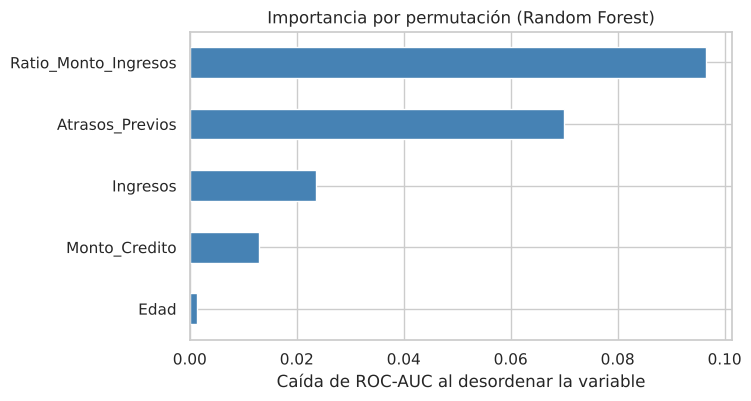

In [10]:
perm = permutation_importance(rf, X_test, y_test, scoring="roc_auc",
                              n_repeats=20, random_state=SEED, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X.columns).sort_values()

imp.plot(kind="barh", color="steelblue", figsize=(7, 4))
plt.title("Importancia por permutación (Random Forest)")
plt.xlabel("Caída de ROC-AUC al desordenar la variable")
plt.show()

## Paso 9: Elegir el umbral de decisión

Por defecto se clasifica como "incumple" si la probabilidad supera 0,5. En riesgo crediticio, no detectar un incumplimiento suele costar más que revisar de más un buen cliente, así que conviene bajar el umbral y ver el compromiso entre recall y clientes marcados.

In [11]:
proba = rf.predict_proba(X_test)[:, 1]
filas = []
for umbral in [0.5, 0.4, 0.3, 0.25, 0.2]:
    pred = (proba >= umbral).astype(int)
    filas.append({"Umbral": umbral,
                  "Precision": precision_score(y_test, pred),
                  "Recall": recall_score(y_test, pred),
                  "% clientes marcados": pred.mean()})
pd.DataFrame(filas).set_index("Umbral").round(3)

,Precision,Recall,% clientes marcados
Umbral,,,
0.50,0.541,0.644,0.345
0.40,0.468,0.707,0.438
0.30,0.420,0.799,0.552
0.25,0.406,0.874,0.623
0.20,0.371,0.908,0.710


## Conclusiones

1. **El accuracy engaña con clases desbalanceadas.** El modelo de referencia acierta ~71 % sin detectar ningún incumplimiento. Por eso se evaluó con recall, F1 y ROC-AUC.
2. **Sin control de complejidad, el árbol sobreajusta:** 100 % de accuracy en entrenamiento contra ~69 % en prueba (ROC-AUC ≈ 0,65).
3. **La optimización importa.** Con `GridSearchCV`, un árbol de profundidad 4 y hojas de al menos 40 casos sube el ROC-AUC a ≈ 0,77 y el F1 a ≈ 0,59, y además es fácil de explicar.
4. **Random Forest obtuvo el mejor ROC-AUC (≈ 0,79) y el mayor recall (≈ 0,64)**, pero su F1 es prácticamente igual al del árbol optimizado y su accuracy es algo menor. Con 600 casos de prueba, diferencias de ~0,02 no son concluyentes. En crédito la interpretabilidad también cuenta, así que el árbol optimizado es un candidato válido.
5. **Los modelos recuperaron las relaciones reales:** la relación monto/ingresos y los atrasos previos dominan la importancia, y la edad casi no aporta, tal como se definió en el proceso generador. (`Ingresos` y `Monto_Credito` aparecen porque componen el ratio.)
6. **El umbral es una decisión de negocio:** bajarlo de 0,5 a 0,3 sube el recall de ≈ 0,64 a ≈ 0,80, pero se marca como riesgoso al ~55 % de los clientes y la precisión cae a ≈ 0,42.

> Los valores corresponden a `SEED = 42` y pueden variar levemente con otras versiones de scikit-learn.

## Limitaciones y próximos pasos

- Los datos son **sintéticos**: sirven para validar el método, pero los resultados no son extrapolables a un banco real, donde hay más ruido, variables faltantes y cambios en el tiempo.
- Probar con un dataset real de riesgo crediticio (por ejemplo *German Credit*, disponible en UCI/OpenML).
- Incorporar el **costo** de cada tipo de error para elegir el umbral de forma cuantitativa.
- Calibrar las probabilidades, explicar predicciones individuales (SHAP) y revisar **equidad**: en crédito real, usar variables como la edad exige un análisis cuidadoso.